# 01 · MC validation

Visual and numerical check of the MC truth generation:

1. **Proton beam**: the sampled variables follow the input Gaussians, and $\sigma_E = (p/E)\,\sigma_p$.
2. **J/ψ → μ⁺μ⁻**: exact invariant mass, momentum conservation, isotropy in the rest frame.
3. **π⁺ → μ⁺ν**: the flight distance follows an exponential with mean $\beta\gamma c\tau$.
4. **Summary**: `assert`s that fail if something breaks.

Parameters are read from `configs/config.yaml`. Units: MeV, mm, rad.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils.config_loader import load_config, make_beam, get_constant
from src.montecarlo.two_body_decay import decay, boost_2d, invariant_mass

cfg = load_config("config")
N, SEED = cfg["run"]["n_events"], cfg["run"]["seed"]
print(f"N = {N}, seed = {SEED}")

N = 100000, seed = 42


In [2]:
# Plot style
SAMPLE   = "#2a78d6"   # MC sample
EXPECTED = "#eb6834"   # expected / analytic curve
SECOND   = "#1baf7a"   # second sample

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#0b0b0b",
    "axes.titlesize": 11,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "legend.frameon": False,
})


def gauss(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))


def hist(ax, data, bins, color=SAMPLE, label="MC", density=True, fill=True):
    if fill:
        ax.hist(data, bins=bins, density=density, histtype="stepfilled",
                color=color, alpha=0.3, edgecolor=color, linewidth=1.2, label=label)
    else:
        ax.hist(data, bins=bins, density=density, histtype="step", color=color, linewidth=1.5, label=label)

## 1. Proton beam

Each histogram is overlaid with the Gaussian built from the input parameters of the YAML.
For $E_0$ the expected width is the first-order propagation, $\sigma_E = (p/E)\,\sigma_p$.

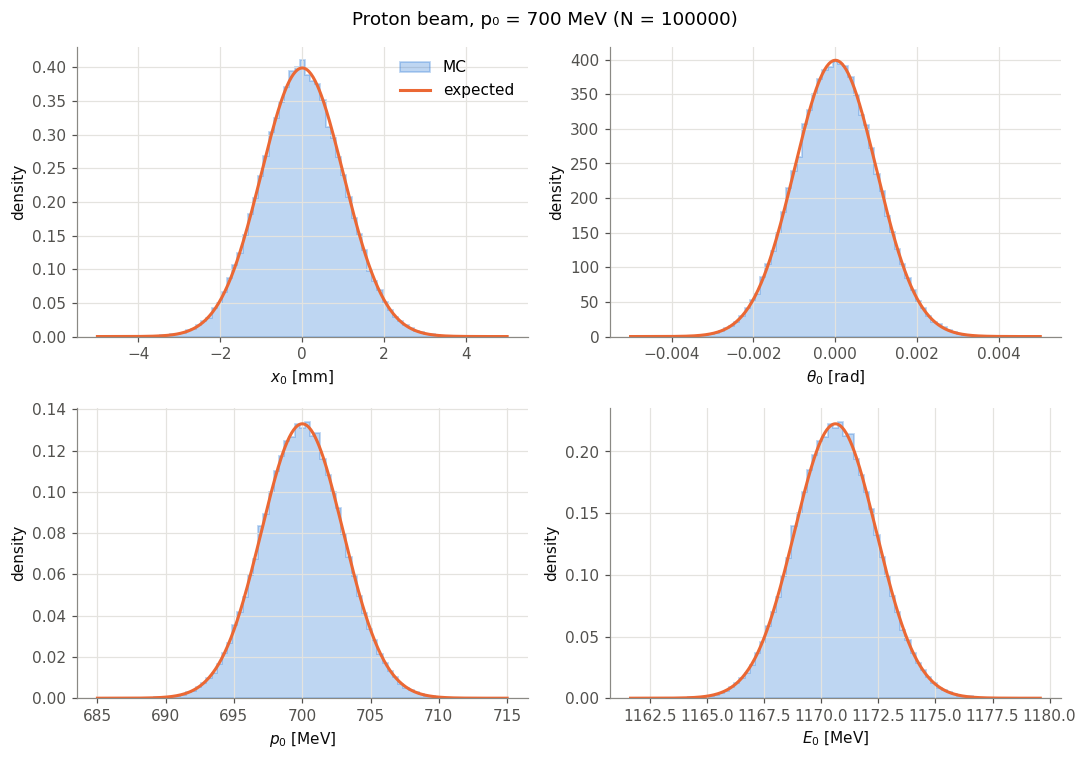

In [3]:
bp = cfg["beams"]["proton"]
df_p = make_beam(bp).generate(N, seed=SEED)
m_p = get_constant(bp["particle"]).mass

E_mean = np.sqrt(bp["p0"]**2 + m_p**2)
sigma_E = bp["p0"] / E_mean * bp["sigma_p0"]

expected = {
    "x0":     (bp["x0"],     bp["sigma_x0"],     r"$x_0$ [mm]"),
    "theta0": (bp["theta0"], bp["sigma_theta0"], r"$\theta_0$ [rad]"),
    "p0":     (bp["p0"],     bp["sigma_p0"],     r"$p_0$ [MeV]"),
    "E0":     (E_mean,       sigma_E,            r"$E_0$ [MeV]"),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (col, (mu, s, label)) in zip(axes.flat, expected.items()):
    x = np.linspace(mu - 5 * s, mu + 5 * s, 400)
    hist(ax, df_p[col], bins=np.linspace(mu - 5 * s, mu + 5 * s, 80))
    ax.plot(x, gauss(x, mu, s), color=EXPECTED, label="expected")
    ax.set_xlabel(label)
    ax.set_ylabel("density")
axes[0, 0].legend()
fig.suptitle(f"Proton beam, p₀ = {bp['p0']:.0f} MeV (N = {N})")
fig.tight_layout()
plt.show()

Input vs. sample table. The *pulls* measure the difference in units of the statistical error:
$\sigma/\sqrt{N}$ for the mean and $\sigma/\sqrt{2N}$ for the standard deviation. They should be $|{\rm pull}| \lesssim 3$.

In [4]:
summary = pd.DataFrame({
    "μ expected": {c: v[0] for c, v in expected.items()},
    "μ sample":  df_p[list(expected)].mean(),
    "σ expected": {c: v[1] for c, v in expected.items()},
    "σ sample":  df_p[list(expected)].std(),
})
summary["pull μ"] = (summary["μ sample"] - summary["μ expected"]) / (summary["σ expected"] / np.sqrt(N))
summary["pull σ"] = (summary["σ sample"] - summary["σ expected"]) / (summary["σ expected"] / np.sqrt(2 * N))
summary

,μ expected,μ sample,σ expected,σ sample,pull μ,pull σ
x0,0.000000,-0.004233,1.000000,1.003708,-1.338570,1.658412
theta0,0.000000,0.000003,0.001000,0.001002,0.859277,0.802206
p0,700.000000,700.004933,3.000000,2.989628,0.519972,-1.546144
E0,1170.621421,1170.626823,1.793919,1.787749,0.952283,-1.538160


## 2. J/ψ → μ⁺μ⁻

### 2.1 Conservation

The invariant mass of each pair and the sum of the daughter momenta must match the parent up to machine precision.

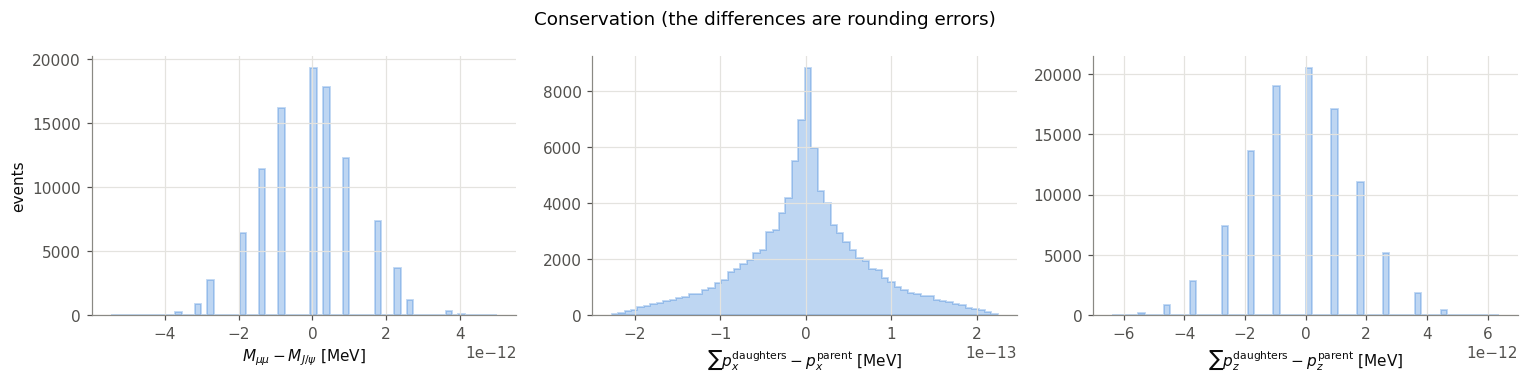

max |ΔM| = 5.46e-12 MeV,  max |Δp| = 6.37e-12 MeV


In [5]:
bj = cfg["beams"]["jpsi"]
ch_j = get_constant(bj["decay"])
df_jpsi = make_beam(bj).generate(N, seed=SEED)
df_mumu = decay(df_jpsi, ch_j, seed=SEED + 1)

dm_j = invariant_mass(df_mumu) - ch_j.parent.mass

sum_d = df_mumu.groupby("event_id")[["px0", "pz0"]].sum()
dp_j = sum_d.to_numpy() - df_jpsi.set_index("event_id").loc[sum_d.index, ["px0", "pz0"]].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
hist(axes[0], dm_j, bins=60, density=False)
axes[0].set_xlabel(r"$M_{\mu\mu} - M_{J/\psi}$ [MeV]")
axes[0].set_ylabel("events")
hist(axes[1], dp_j[:, 0], bins=60, density=False)
axes[1].set_xlabel(r"$\sum p_x^{\rm daughters} - p_x^{\rm parent}$ [MeV]")
hist(axes[2], dp_j[:, 1], bins=60, density=False)
axes[2].set_xlabel(r"$\sum p_z^{\rm daughters} - p_z^{\rm parent}$ [MeV]")
fig.suptitle("Conservation (the differences are rounding errors)")
fig.tight_layout()
plt.show()

print(f"max |ΔM| = {np.abs(dm_j).max():.2e} MeV,  max |Δp| = {np.abs(dp_j).max():.2e} MeV")

### 2.2 Isotropy in the rest frame

The μ⁺ are boosted back with the velocity of their J/ψ. The angle $\alpha^*$ must be uniform in $[-\pi, \pi]$
and the magnitude $p^*$ equal to the two-body value,
$p^* = \sqrt{(M^2-(m_1+m_2)^2)(M^2-(m_1-m_2)^2)}\,/\,2M$.

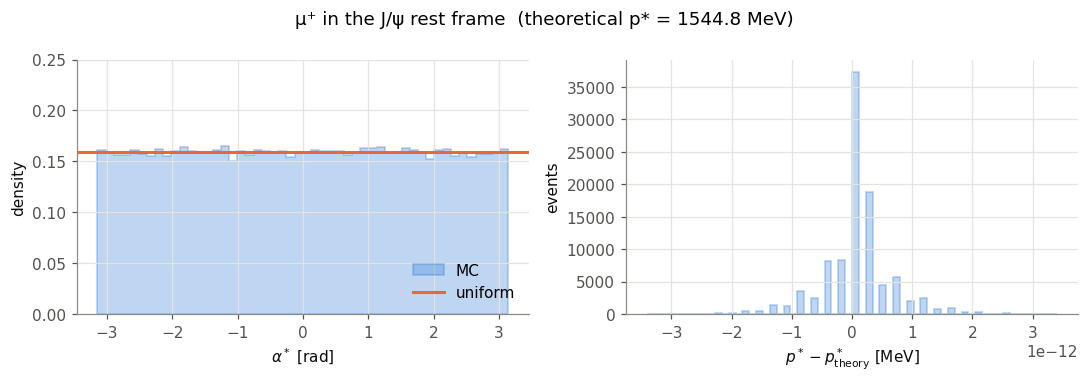

In [6]:
mu_plus = df_mumu[df_mumu["particle"] == ch_j.daughters[0].name].set_index("event_id")
par = df_jpsi.set_index("event_id").loc[mu_plus.index]

_, px_s, pz_s = boost_2d(
    mu_plus["E0"].to_numpy(), mu_plus["px0"].to_numpy(), mu_plus["pz0"].to_numpy(),
    -(par["px0"] / par["E0"]).to_numpy(), -(par["pz0"] / par["E0"]).to_numpy(),
)
alpha_star = np.arctan2(px_s, pz_s)
p_star = np.hypot(px_s, pz_s)

M, m1, m2 = ch_j.parent.mass, ch_j.daughters[0].mass, ch_j.daughters[1].mass
p_star_th = np.sqrt((M**2 - (m1 + m2)**2) * (M**2 - (m1 - m2)**2)) / (2 * M)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
hist(axes[0], alpha_star, bins=np.linspace(-np.pi, np.pi, 51))
axes[0].axhline(1 / (2 * np.pi), color=EXPECTED, label="uniform")
axes[0].set_xlabel(r"$\alpha^*$ [rad]")
axes[0].set_ylabel("density")
axes[0].set_ylim(0, 0.25)
axes[0].legend(loc="lower right")
hist(axes[1], p_star - p_star_th, bins=60, density=False)
axes[1].set_xlabel(r"$p^* - p^*_{\rm theory}$ [MeV]")
axes[1].set_ylabel("events")
fig.suptitle(f"μ⁺ in the J/ψ rest frame  (theoretical p* = {p_star_th:.1f} MeV)")
fig.tight_layout()
plt.show()

### 2.3 Muons in the lab frame

For a J/ψ of a few GeV the muons come out with a wide opening angle. The shaded region ($|\theta| > \pi/2$, i.e. $p_z < 0$)
contains backward-going muons: a Kalman filter stepping along $z$ cannot follow them. An acceptance cut will be needed.

The $p$ spectrum has two peaks at its edges, which is expected in 2D. With uniform $\alpha^*$, $p_\parallel^* = p^*\cos\alpha^*$
piles up at $\pm p^*$ (arcsine distribution). In 3D, with uniform $\cos\theta^*$, the spectrum would be flat between the two edges.

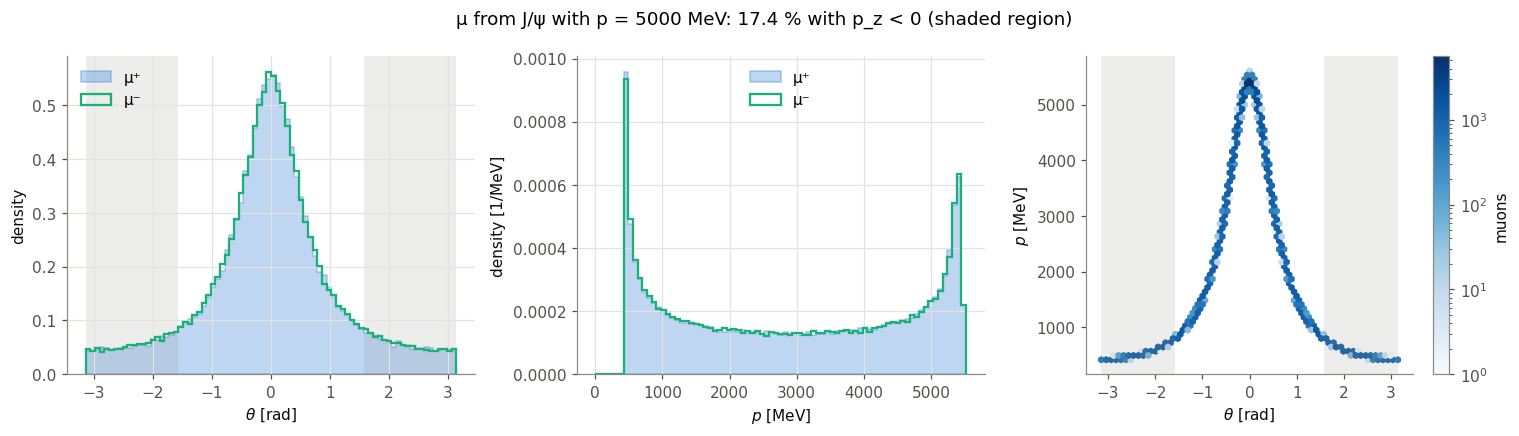

In [7]:
mu_minus = df_mumu[df_mumu["particle"] == ch_j.daughters[1].name]
frac_back = (df_mumu["pz0"] < 0).mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

bins_th = np.linspace(-np.pi, np.pi, 81)
hist(axes[0], mu_plus["theta0"], bins=bins_th, label="μ⁺")
hist(axes[0], mu_minus["theta0"], bins=bins_th, color=SECOND, label="μ⁻", fill=False)
axes[0].set_xlabel(r"$\theta$ [rad]")
axes[0].set_ylabel("density")
axes[0].legend(loc="upper left")

bins_p = np.linspace(0, df_mumu["p0"].quantile(0.999), 80)
hist(axes[1], mu_plus["p0"], bins=bins_p, label="μ⁺")
hist(axes[1], mu_minus["p0"], bins=bins_p, color=SECOND, label="μ⁻", fill=False)
axes[1].set_xlabel(r"$p$ [MeV]")
axes[1].set_ylabel("density [1/MeV]")
axes[1].legend(loc="upper center")

hb = axes[2].hexbin(df_mumu["theta0"], df_mumu["p0"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
axes[2].set_xlabel(r"$\theta$ [rad]")
axes[2].set_ylabel(r"$p$ [MeV]")
axes[2].grid(False)
fig.colorbar(hb, ax=axes[2], label="muons")

for ax in axes[[0, 2]]:
    for lo, hi in [(-np.pi, -np.pi / 2), (np.pi / 2, np.pi)]:
        ax.axvspan(lo, hi, color="#8a8984", alpha=0.15, linewidth=0)

fig.suptitle(f"μ from J/ψ with p = {bj['p0']:.0f} MeV: {100 * frac_back:.1f} % with p_z < 0 (shaded region)")
fig.tight_layout()
plt.show()

## 3. π⁺ → μ⁺ν: flight distance

Each pion travels $L \sim {\rm Exp}(\lambda_i)$ with $\lambda_i = (p_i/m)\,c\tau$. Since $p$ varies from event to event,
the expected distribution is the average of the exponentials, $f(L) = \frac{1}{N}\sum_i e^{-L/\lambda_i}/\lambda_i$.

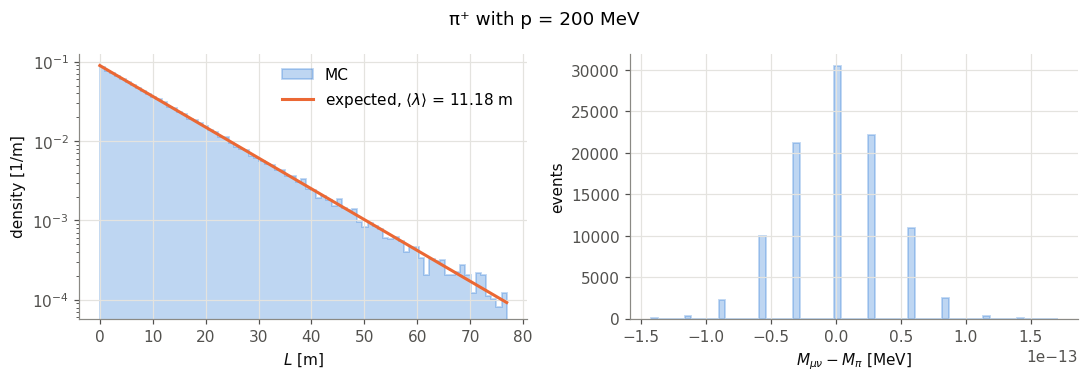

<L> sample = 11180 mm,  <λ> expected = 11184 mm


In [8]:
bpi = cfg["beams"]["pion"]
ch_pi = get_constant(bpi["decay"])
df_pi = make_beam(bpi).generate(N, seed=SEED)
df_munu = decay(df_pi, ch_pi, seed=SEED + 2)

vtx = df_munu.groupby("event_id")[["x0", "z0"]].first()
par_pi = df_pi.set_index("event_id").loc[vtx.index]
L = np.hypot(vtx["x0"] - par_pi["x0"], vtx["z0"] - par_pi["z0"]).to_numpy()
lam = (par_pi["p0"] / ch_pi.parent.mass * ch_pi.parent.ctau).to_numpy()

x = np.linspace(0, np.quantile(L, 0.999), 300)
f_L = np.mean(np.exp(-x[:, None] / lam) / lam, axis=1)

dm_pi = invariant_mass(df_munu) - ch_pi.parent.mass

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
hist(axes[0], L / 1000, bins=np.linspace(0, x[-1] / 1000, 80))
axes[0].plot(x / 1000, f_L * 1000, color=EXPECTED, label=r"expected, $\langle\lambda\rangle$" + f" = {lam.mean() / 1000:.2f} m")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"$L$ [m]")
axes[0].set_ylabel("density [1/m]")
axes[0].legend()
hist(axes[1], dm_pi, bins=60, density=False)
axes[1].set_xlabel(r"$M_{\mu\nu} - M_{\pi}$ [MeV]")
axes[1].set_ylabel("events")
fig.suptitle(f"π⁺ with p = {bpi['p0']:.0f} MeV")
fig.tight_layout()
plt.show()

print(f"<L> sample = {L.mean():.0f} mm,  <λ> expected = {lam.mean():.0f} mm")

## 4. Summary

If any check fails, the cell raises an `AssertionError`.

In [9]:
TOL = 1e-6   # MeV, numerical precision
PULL = 5     # statistical tolerance, in sigmas

# 1. Proton beam
assert (summary[["pull μ", "pull σ"]].abs() < PULL).all().all(), "beam moments off"

# 2. J/psi -> mu mu
assert np.abs(dm_j).max() < TOL, "J/psi invariant mass not conserved"
assert np.abs(dp_j).max() < TOL, "J/psi momentum not conserved"
assert np.abs(p_star - p_star_th).max() < TOL, "wrong p* in the rest frame"
counts, _ = np.histogram(alpha_star, bins=50, range=(-np.pi, np.pi))
chi2_ndf = np.sum((counts - N / 50) ** 2 / (N / 50)) / 49
assert chi2_ndf < 2, f"alpha* not uniform (chi2/ndf = {chi2_ndf:.2f})"

# 3. pi -> mu nu
pull_L = (L.mean() - lam.mean()) / (np.sqrt(np.sum(lam**2)) / N)
assert abs(pull_L) < PULL, f"decay length off (pull = {pull_L:.2f})"
assert np.abs(dm_pi).max() < TOL, "pi invariant mass not conserved"

print(f"chi2/ndf(alpha*) = {chi2_ndf:.2f},  pull <L> = {pull_L:.2f}")
print("All checks passed ✓")

chi2/ndf(alpha*) = 0.73,  pull <L> = -0.10
All checks passed ✓
